In [1]:
import os
import kagglehub
import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

In [2]:
# 1. Загружаем данные
path = kagglehub.competition_download("playground-series-s6e11")
train_df = pd.read_csv(os.path.join(path, "train.csv"))
test_df = pd.read_csv(os.path.join(path, "test.csv"))

In [3]:
# 2. Отделяем признаки (X) от ответов (y), а также готовим тестовую таблицу
X = train_df.drop(columns=["id", "is_fraud"])
y = train_df["is_fraud"]
X_test = test_df.drop(columns=["id"])

In [4]:
# 3. МАГИЯ LightGBM: Никаких сложных трансформеров!
# Просто переводим текстовые и логические колонки в специальный тип 'category'
cat_cols = X.select_dtypes(include=["object", "bool"]).columns.tolist()

for col in cat_cols:
    X[col] = X[col].astype("category")
    X_test[col] = X_test[col].astype("category")

In [5]:
# 4. Делим данные на обучение (80%) и проверку (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [6]:
# 5. Создаем модель LightGBM
model = lgb.LGBMClassifier(
    n_estimators=1000,  # Задаем с запасом 1000 деревьев (лишние отсечет ранняя остановка)
    learning_rate=0.05,  # Скорость обучения (шаг, с которым каждое дерево исправляет ошибки)
    class_weight="balanced",  # Автоматический учет дисбаланса (1.67% мошенников)
    random_state=42,
    n_jobs=-1,  # Используем все ядра процессора
)

In [7]:
# 6. Обучаем модель с умной остановкой (Early Stopping)
print("Начинаем обучение...")
model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],  # Даем проверочную выборку для контроля качества
    eval_metric="auc",  # Следим за метрикой ROC-AUC
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50
        ),  # Стоп, если за 50 деревьев метрика не выросла
        lgb.log_evaluation(
            period=100
        ),  # Печатать результат каждого 100-го дерева
    ],
)

Начинаем обучение...
[LightGBM] [Info] Number of positive: 9351, number of negative: 550617
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.128320 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1749
[LightGBM] [Info] Number of data points in the train set: 559968, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Training until validation scores don't improve for 50 rounds
[100]	valid_0's auc: 0.941549	valid_0's binary_logloss: 0.29236
[200]	valid_0's auc: 0.943045	valid_0's binary_logloss: 0.269508
Early stopping, best iteration is:
[238]	valid_0's auc: 0.943186	valid_0's binary_logloss: 0.26356


LGBMClassifier(class_weight='balanced', learning_rate=0.05, n_estimators=1000,
               n_jobs=-1, random_state=42)

In [8]:
# 7. Проверяем итоговое качество на валидации
# Берем второй столбец [:, 1] — это вероятность класса 1 (мошенничество)
val_preds = model.predict_proba(X_val)[:, 1]
score = roc_auc_score(y_val, val_preds)
print(f"\nИтоговая точность LightGBM (ROC-AUC): {score:.4f}")


Итоговая точность LightGBM (ROC-AUC): 0.9432


In [9]:
# 8. Делаем предсказание для тестового файла и сохраняем результат
test_preds = model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({"id": test_df["id"], "is_fraud": test_preds})
submission.to_csv("lgbm_submission.csv", index=False)
print("Файл lgbm_submission.csv успешно готов к отправке на Kaggle!")

Файл lgbm_submission.csv успешно готов к отправке на Kaggle!


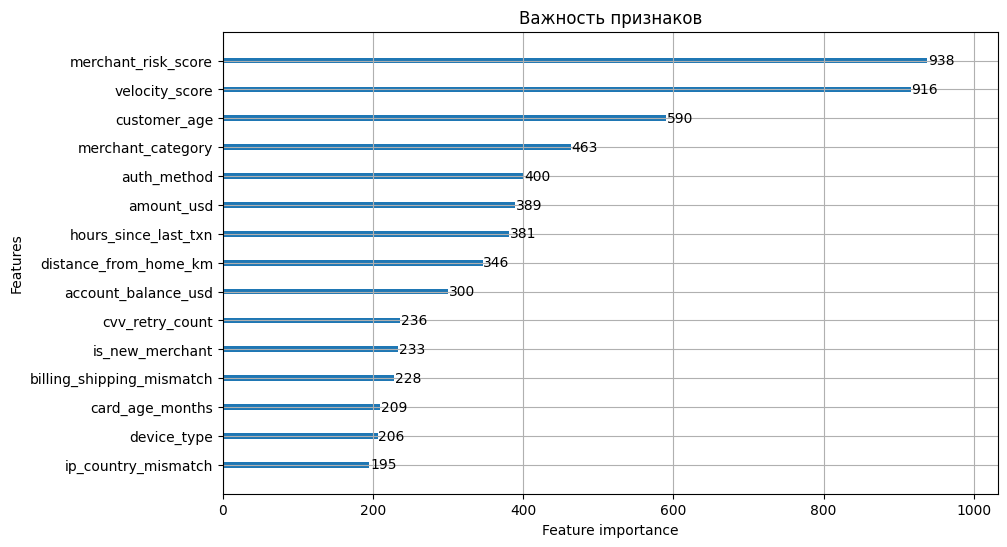

In [10]:
# Рисуем топ-15 самых важных колонок таблицы
lgb.plot_importance(
    model, max_num_features=15, figsize=(10, 6), title="Важность признаков"
)
plt.show()